<a href="https://colab.research.google.com/github/ayushunhale10-code/AI-ML-Assignments/blob/main/Assignment-10/Assignment_10_Fake_News.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 10: Fake News Detection Using Multimodal Data

## Aim

To demonstrate fake news detection by combining news text with image-caption information using machine learning.

## Theory

Fake news refers to false or misleading information presented as news. Machine learning can help classify news articles using patterns in their text and associated image information.

Multimodal learning combines information from different sources, such as text and images. In this practical, news text and image-caption descriptions are combined into a single input. TF-IDF converts the text into numerical features, and Logistic Regression classifies the examples as real or fake.

The dataset used here is a small illustrative dataset. A real-world system requires a larger, verified dataset and actual image features or image embeddings.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
data = {
    "news_text": [
        "The city council approved a new public library after a public meeting.",
        "The national weather agency issued a heavy rain warning for the region.",
        "Researchers published a study on renewable energy in a scientific journal.",
        "The health department announced a vaccination awareness campaign.",
        "The school board released the official examination timetable.",
        "The railway department announced a revised train schedule.",
        "The government published its annual economic report.",
        "The university opened registration for its science conference.",
        "The space agency reported the successful launch of a research satellite.",
        "The election commission released official voting dates.",
        "Officials confirmed that aliens secretly control every world government.",
        "A miracle drink reportedly makes everyone immortal overnight.",
        "A viral post claims the moon will disappear for seven days.",
        "A secret message claims all banks will permanently close tomorrow.",
        "A fabricated report says eating one fruit cures every disease.",
        "An online rumour claims gravity will stop working next week.",
        "A viral message says every student will receive one million rupees tomorrow.",
        "A sensational post claims humans can live without water forever.",
        "An unverified post claims a hidden planet will hit Earth tonight.",
        "A fabricated story claims ordinary phones can predict lottery numbers."
    ],
    "image_caption": [
        "Photo of a library building and city officials at a meeting.",
        "Weather map showing a regional rain warning.",
        "Researchers working with solar panels in a laboratory.",
        "Healthcare workers conducting a public awareness event.",
        "Official timetable displayed on a school notice board.",
        "Train standing at a railway platform.",
        "Officials presenting a printed economic report.",
        "Students attending a university science conference.",
        "Rocket launching from a space centre.",
        "Election officials displaying a voting schedule.",
        "Edited image showing imaginary aliens inside a government building.",
        "Unverified promotional image of a miracle drink.",
        "Dramatic edited picture of a disappearing moon.",
        "Fake bank closure notice shared on social media.",
        "Misleading advertisement showing fruit as a universal cure.",
        "Edited illustration showing people floating in the air.",
        "Fake money distribution poster circulating online.",
        "Unverified image claiming humans no longer need water.",
        "Edited picture of a fictional planet near Earth.",
        "Fake advertisement claiming a phone predicts lottery results."
    ],
    "label": [
        "Real", "Real", "Real", "Real", "Real",
        "Real", "Real", "Real", "Real", "Real",
        "Fake", "Fake", "Fake", "Fake", "Fake",
        "Fake", "Fake", "Fake", "Fake", "Fake"
    ]
}

df = pd.DataFrame(data)

print("Dataset created successfully.")
display(df.head())

Dataset created successfully.


,news_text,image_caption,label
0,The city council approved a new public library...,Photo of a library building and city officials...,Real
1,The national weather agency issued a heavy rai...,Weather map showing a regional rain warning.,Real
2,Researchers published a study on renewable ene...,Researchers working with solar panels in a lab...,Real
3,The health department announced a vaccination ...,Healthcare workers conducting a public awarene...,Real
4,The school board released the official examina...,Official timetable displayed on a school notic...,Real


In [3]:
print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())

display(df)

Dataset shape: (20, 3)

Class distribution:
label
Real    10
Fake    10
Name: count, dtype: int64


,news_text,image_caption,label
0,The city council approved a new public library...,Photo of a library building and city officials...,Real
1,The national weather agency issued a heavy rai...,Weather map showing a regional rain warning.,Real
2,Researchers published a study on renewable ene...,Researchers working with solar panels in a lab...,Real
3,The health department announced a vaccination ...,Healthcare workers conducting a public awarene...,Real
4,The school board released the official examina...,Official timetable displayed on a school notic...,Real
5,The railway department announced a revised tra...,Train standing at a railway platform.,Real
6,The government published its annual economic r...,Officials presenting a printed economic report.,Real
7,The university opened registration for its sci...,Students attending a university science confer...,Real
8,The space agency reported the successful launc...,Rocket launching from a space centre.,Real
9,The election commission released official voti...,Election officials displaying a voting schedule.,Real


In [4]:
df["combined_input"] = (
    "News: " + df["news_text"] +
    " Image caption: " + df["image_caption"]
)

X = df["combined_input"]
y = df["label"]

print("News text and image-caption information combined.")
print("\nExample combined input:")
print(X.iloc[0])

News text and image-caption information combined.

Example combined input:
News: The city council approved a new public library after a public meeting. Image caption: Photo of a library building and city officials at a meeting.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 15
Testing samples: 5


In [6]:
vectorizer = TfidfVectorizer(stop_words="english")

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Text converted into numerical features.")
print("Training feature shape:", X_train_tfidf.shape)

Text converted into numerical features.
Training feature shape: (15, 139)


In [7]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

print("Fake news classification model trained successfully.")

Fake news classification model trained successfully.


In [8]:
y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 80.0 %

Classification Report:
              precision    recall  f1-score   support

        Fake       1.00      0.67      0.80         3
        Real       0.67      1.00      0.80         2

    accuracy                           0.80         5
   macro avg       0.83      0.83      0.80         5
weighted avg       0.87      0.80      0.80         5



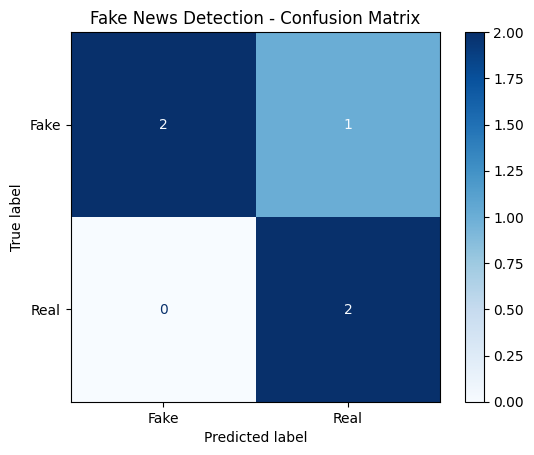

In [9]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["Fake", "Real"],
    cmap="Blues"
)

plt.title("Fake News Detection - Confusion Matrix")
plt.show()

In [10]:
sample_news = "Officials announced a new public education programme."
sample_image_caption = "Photo showing officials at a school event."

sample_combined = [
    "News: " + sample_news +
    " Image caption: " + sample_image_caption
]

sample_features = vectorizer.transform(sample_combined)
prediction = model.predict(sample_features)[0]

print("News:", sample_news)
print("Image caption:", sample_image_caption)
print("Predicted category:", prediction)

News: Officials announced a new public education programme.
Image caption: Photo showing officials at a school event.
Predicted category: Real


## Result Interpretation

The news text and image-caption descriptions were combined and converted into numerical features using TF-IDF. A Logistic Regression classifier was trained to classify the sample entries as Real or Fake. The model's performance was evaluated using accuracy, a classification report, and a confusion matrix.

## Result

A basic fake news classification model was implemented using combined news text and image-caption information. The model generated predictions for the test data and a sample news item.

## Conclusion

In this practical, machine learning was used to demonstrate fake news classification using news text and associated image-caption information. TF-IDF was used for feature extraction, and Logistic Regression was used for classification. This small illustrative experiment demonstrates how information from multiple sources can be combined. Reliable real-world fake news detection requires verified datasets, actual image analysis, and careful evaluation.